# Customer Review Sentiment Analysis using NLP and LSTM

**Project:** Classify movie/customer reviews (IMDB dataset) as **Positive** or **Negative**
using text preprocessing, traditional NLP feature representations (Bag of Words, TF-IDF), and a
deep learning **LSTM** classifier.

This notebook covers all five assignment tasks:
1. Text data preparation (cleaning, tokenization, stopwords, stemming, sequences, padding)
2. Text representation (Bag of Words, TF-IDF, Word Embeddings) and how they differ
3. LSTM model development
4. Model evaluation (accuracy, precision, recall, F1, confusion matrix)
5. Performance analysis (sequence length, embeddings, LSTM memory, overfitting, limitations)


## 0. Setup & Imports

In [ ]:
import os
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix)

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('wordnet', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

os.makedirs("output_images", exist_ok=True)

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)


TensorFlow version: 2.20.0
GPU available: []


## Task 1 — Text Data Preparation

The Keras IMDB dataset ships **pre-tokenized as integers** (each word already mapped to an ID,
ranked by frequency). To actually demonstrate manual text cleaning, tokenization, stopword
removal, and stemming/lemmatization (as the assignment requires), we first **decode a sample of
reviews back to raw text** using Keras's word index, run the classic NLP preprocessing pipeline
on that raw text, and then proceed with the standard integer-sequence + padding approach (the
efficient, standard way LSTMs consume this dataset) for actually training the model.


In [ ]:
VOCAB_SIZE = 10000
MAX_LEN = 200  # sequence length after padding/truncation

(X_train, y_train), (X_test, y_test) = keras.datasets.imdb.load_data(num_words=VOCAB_SIZE)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Example (integer-encoded) review, first 10 tokens:", X_train[0][:10])
print("Label (0=negative, 1=positive):", y_train[0])


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training samples: 25000
Testing samples: 25000
Example (integer-encoded) review, first 10 tokens: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65]
Label (0=negative, 1=positive): 1


In [ ]:
# Decode integer sequences back to raw text, for demonstrating manual preprocessing
word_index = keras.datasets.imdb.get_word_index()
# Keras reserves indices 0-3 for padding/start/unknown/unused
reverse_word_index = {v + 3: k for k, v in word_index.items()}
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"
reverse_word_index[3] = "<UNUSED>"

def decode_review(encoded_review):
    return " ".join(reverse_word_index.get(i, "?") for i in encoded_review)

sample_raw_texts = [decode_review(X_train[i]) for i in range(5)]
for i, text in enumerate(sample_raw_texts):
    print(f"--- Review {i+1} (label={y_train[i]}) ---")
    print(text[:300], "...\n")


1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
--- Review 1 (label=1) ---
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the ...

--- Review 2 (label=0) ---
<START> big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and ridiculous the acting is an abomination the script is co ...

--- Review 3 (label=0) ---
<START> this has to be one of the worst films of the 1990s when my friends i were watching this film being the target audience it was aimed at we just sat watched the first half an hour with our jaws touching the floor at how bad it really was the rest of th

In [ ]:
# --- Manual text cleaning, tokenization, stopword removal, stemming/lemmatization ---
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.replace("<START>", "").replace("<UNK>", "").replace("<PAD>", "")
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)  # remove punctuation/numbers
    text = re.sub(r"\s+", " ", text).strip()
    return text

def preprocess_pipeline(text):
    cleaned = clean_text(text)
    tokens = cleaned.split()                                    # tokenization
    tokens_no_stop = [t for t in tokens if t not in stop_words]  # stopword removal
    stemmed = [stemmer.stem(t) for t in tokens_no_stop]           # stemming
    lemmatized = [lemmatizer.lemmatize(t) for t in tokens_no_stop]  # lemmatization (alternative)
    return {
        "cleaned_text": cleaned,
        "tokens": tokens,
        "tokens_no_stopwords": tokens_no_stop,
        "stemmed_tokens": stemmed,
        "lemmatized_tokens": lemmatized,
    }

demo = preprocess_pipeline(sample_raw_texts[0])
print("Cleaned text (first 200 chars):", demo["cleaned_text"][:200])
print("\nTokens (first 15):", demo["tokens"][:15])
print("\nAfter stopword removal (first 15):", demo["tokens_no_stopwords"][:15])
print("\nAfter stemming (first 15):", demo["stemmed_tokens"][:15])
print("\nAfter lemmatization (first 15):", demo["lemmatized_tokens"][:15])


Cleaned text (first 200 chars): this film was just brilliant casting location scenery story direction everyones really suited the part they played and you could just imagine being there robert is an amazing actor and now the same be

Tokens (first 15): ['this', 'film', 'was', 'just', 'brilliant', 'casting', 'location', 'scenery', 'story', 'direction', 'everyones', 'really', 'suited', 'the', 'part']

After stopword removal (first 15): ['film', 'brilliant', 'casting', 'location', 'scenery', 'story', 'direction', 'everyones', 'really', 'suited', 'part', 'played', 'could', 'imagine', 'robert']

After stemming (first 15): ['film', 'brilliant', 'cast', 'locat', 'sceneri', 'stori', 'direct', 'everyon', 'realli', 'suit', 'part', 'play', 'could', 'imagin', 'robert']

After lemmatization (first 15): ['film', 'brilliant', 'casting', 'location', 'scenery', 'story', 'direction', 'everyones', 'really', 'suited', 'part', 'played', 'could', 'imagine', 'robert']


**Word indexing, sequence generation, and padding** — for actually feeding the LSTM, we use
Keras's built-in integer encoding (already applied above via `num_words=10000`, which keeps only
the 10,000 most frequent words — this IS the "word indexing" step) plus `pad_sequences` to make
every review the same length.


In [ ]:
# Pad/truncate all sequences to MAX_LEN
X_train_padded = pad_sequences(X_train, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_padded = pad_sequences(X_test, maxlen=MAX_LEN, padding='post', truncating='post')

print("Padded training shape:", X_train_padded.shape)
print("Padded testing shape:", X_test_padded.shape)

# Train/test split is already provided by imdb.load_data(); carve a validation set from training
VAL_SPLIT = 0.1
n_val = int(len(X_train_padded) * VAL_SPLIT)

X_val, y_val = X_train_padded[:n_val], y_train[:n_val]
X_train_final, y_train_final = X_train_padded[n_val:], y_train[n_val:]

print(f"Train: {X_train_final.shape} | Validation: {X_val.shape} | Test: {X_test_padded.shape}")


Padded training shape: (25000, 200)
Padded testing shape: (25000, 200)
Train: (22500, 200) | Validation: (2500, 200) | Test: (25000, 200)


## Task 2 — Text Representation

Comparing three ways of turning text into numbers, from traditional/sparse to modern/dense:


In [ ]:
# Build a small raw-text corpus (decoded) to demonstrate BoW / TF-IDF on real words
# (using a subset for speed -- these are demonstration representations, not used to train the LSTM)
DEMO_SIZE = 2000
demo_texts = [clean_text(decode_review(X_train[i])) for i in range(DEMO_SIZE)]
demo_labels = y_train[:DEMO_SIZE]

# --- Bag of Words ---
bow_vectorizer = CountVectorizer(max_features=5000, stop_words='english')
X_bow = bow_vectorizer.fit_transform(demo_texts)
print("Bag of Words matrix shape:", X_bow.shape)
print("Sample vocabulary:", list(bow_vectorizer.vocabulary_.keys())[:10])

# --- TF-IDF ---
tfidf_vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_tfidf = tfidf_vectorizer.fit_transform(demo_texts)
print("\nTF-IDF matrix shape:", X_tfidf.shape)


Bag of Words matrix shape: (2000, 5000)
Sample vocabulary: ['film', 'just', 'brilliant', 'casting', 'location', 'scenery', 'story', 'direction', 'everyones', 'really']

TF-IDF matrix shape: (2000, 5000)


In [ ]:
# Quick baseline: Logistic Regression on TF-IDF features (traditional NLP approach)
# This gives us a real comparison point for the LSTM's deep-learning approach in Task 5.
from sklearn.model_selection import train_test_split

X_tfidf_train, X_tfidf_test, y_tfidf_train, y_tfidf_test = train_test_split(
    X_tfidf, demo_labels, test_size=0.2, random_state=SEED
)

baseline_clf = LogisticRegression(max_iter=1000)
baseline_clf.fit(X_tfidf_train, y_tfidf_train)
baseline_preds = baseline_clf.predict(X_tfidf_test)
baseline_acc = accuracy_score(y_tfidf_test, baseline_preds)

print(f"Baseline TF-IDF + Logistic Regression accuracy (on {DEMO_SIZE}-review subset): {baseline_acc:.4f}")
print("(This is a small-subset baseline for comparison -- the LSTM below trains on the full 25,000 reviews.)")


Baseline TF-IDF + Logistic Regression accuracy (on 2000-review subset): 0.8450
(This is a small-subset baseline for comparison -- the LSTM below trains on the full 25,000 reviews.)


### Word Embeddings (used inside the LSTM model below)

Unlike Bag of Words and TF-IDF — which produce large, **sparse** vectors (one dimension per
vocabulary word, mostly zeros, with no notion of word *meaning* or order) — **word embeddings**
map each word to a small, **dense**, learned vector (e.g. 128 dimensions) where semantically
similar words end up close together in the vector space. Critically, embeddings are learned
*from the task itself* (or pretrained separately), and unlike BoW/TF-IDF, an `Embedding` layer
feeding into an LSTM also **preserves word order**, which matters enormously for sentiment (e.g.
"not good" vs "good").

| | Bag of Words | TF-IDF | Word Embeddings |
|---|---|---|---|
| Vector type | Sparse, one-hot-ish counts | Sparse, weighted by importance | Dense, learned |
| Dimensionality | = vocabulary size (large) | = vocabulary size (large) | Small, fixed (e.g. 128) |
| Captures word order | No | No | Yes (when fed into RNN/LSTM) |
| Captures word meaning/similarity | No | No | Yes |
| Used by | Traditional ML (Logistic Regression, Naive Bayes, SVM) | Traditional ML | Deep learning (RNN, LSTM, Transformers) |


## Task 3 — LSTM Model Development

`Embedding -> LSTM -> Dense -> Sigmoid`, as specified.


In [ ]:
EMBEDDING_DIM = 128

lstm_model = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
    layers.LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
], name="lstm_sentiment_classifier")

lstm_model.build((None, MAX_LEN))
lstm_model.summary()


Model: "lstm_sentiment_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,331,521 (5.08 MB)

 Trainable params: 1,331,521 (5.08 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint('lstm_best_model.h5', monitor='val_accuracy', save_best_only=True)
]

EPOCHS = 10
BATCH_SIZE = 128

history = lstm_model.fit(
    X_train_final, y_train_final,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks
)


Epoch 1/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 450ms/step - accuracy: 0.5095 - loss: 0.6928

176/176 ━━━━━━━━━━━━━━━━━━━━ 86s 466ms/step - accuracy: 0.5166 - loss: 0.6925 - val_accuracy: 0.4896 - val_loss: 0.6938
Epoch 2/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 438ms/step - accuracy: 0.5225 - loss: 0.6914

176/176 ━━━━━━━━━━━━━━━━━━━━ 83s 468ms/step - accuracy: 0.5390 - loss: 0.6874 - val_accuracy: 0.5996 - val_loss: 0.6608
Epoch 3/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step - accuracy: 0.6203 - loss: 0.6397

176/176 ━━━━━━━━━━━━━━━━━━━━ 78s 441ms/step - accuracy: 0.6846 - loss: 0.5975 - val_accuracy: 0.7840 - val_loss: 0.5221
Epoch 4/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 442ms/step - accuracy: 0.7672 - loss: 0.5339

176/176 ━━━━━━━━━━━━━━━━━━━━ 81s 458ms/step - accuracy: 0.7841 - loss: 0.5066 - val_accuracy: 0.8004 - val_loss: 0.4978
Epoch 5/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 82s 460ms/step - accuracy: 0.7812 - loss: 0.5115 - val_accuracy: 0.7320 - val_loss: 0.6014
Epoch 6/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 78s 445ms/step - accuracy: 0.8158 - loss: 0.4599 - val_accuracy: 0.7116 - val_loss: 0.5925
Epoch 7/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 77s 439ms/step - accuracy: 0.6747 - loss: 0.5811 - val_accuracy: 0.6916 - val_loss: 0.6073


## Task 4 — Model Evaluation

In [ ]:
test_loss, test_acc = lstm_model.evaluate(X_test_padded, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

y_probs = lstm_model.predict(X_test_padded, verbose=0).flatten()
y_preds = (y_probs > 0.5).astype(int)

precision = precision_score(y_test, y_preds)
recall = recall_score(y_test, y_preds)
f1 = f1_score(y_test, y_preds)

print(f"\nPrecision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_preds, target_names=['Negative', 'Positive']))


Test Loss: 0.5264
Test Accuracy: 0.7826

Precision: 0.7615
Recall:    0.8228
F1 Score:  0.7910

Classification Report:
              precision    recall  f1-score   support

    Negative       0.81      0.74      0.77     12500
    Positive       0.76      0.82      0.79     12500

    accuracy                           0.78     25000
   macro avg       0.78      0.78      0.78     25000
weighted avg       0.78      0.78      0.78     25000



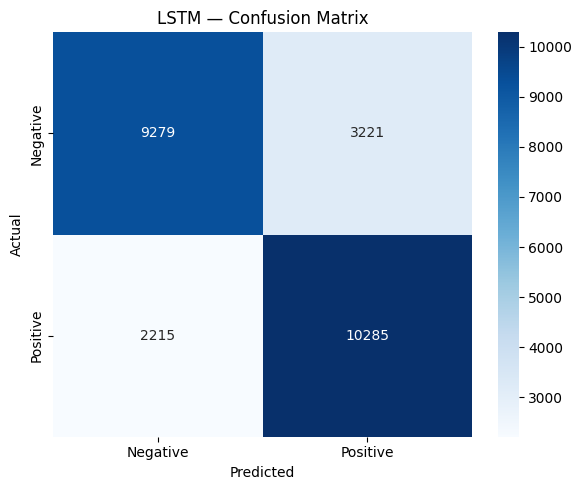

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('LSTM — Confusion Matrix')
plt.tight_layout()
plt.savefig("output_images/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()


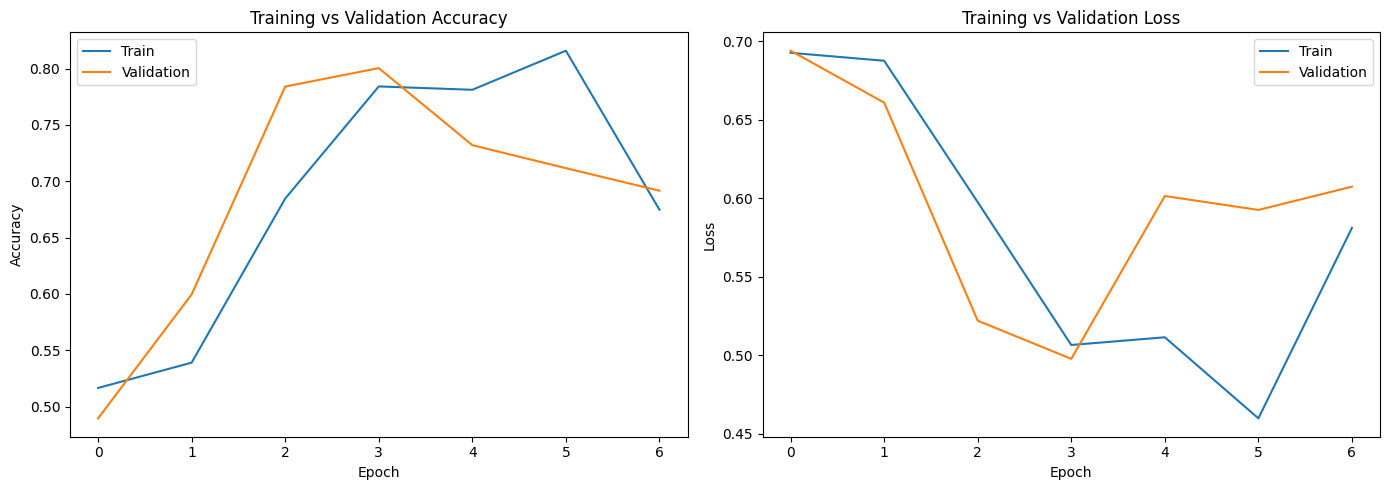

In [ ]:
# Training vs Validation Accuracy & Loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set_title('Training vs Validation Accuracy')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy'); axes[0].legend()

axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set_title('Training vs Validation Loss')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss'); axes[1].legend()

plt.tight_layout()
plt.savefig("output_images/training_curves.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# Actual vs Predicted sentiment comparison on a handful of test reviews
print(f"{'Review (truncated)':<80} {'Actual':<10} {'Predicted':<10} {'Confidence'}")
print("-" * 115)
for i in range(10):
    review_text = decode_review(X_test[i])
    review_preview = review_text[:75].replace("<START>", "").strip() + "..."
    actual = "Positive" if y_test[i] == 1 else "Negative"
    predicted = "Positive" if y_preds[i] == 1 else "Negative"
    confidence = y_probs[i] if y_preds[i] == 1 else 1 - y_probs[i]
    print(f"{review_preview:<80} {actual:<10} {predicted:<10} {confidence:.2%}")


Review (truncated)                                                               Actual     Predicted  Confidence
-------------------------------------------------------------------------------------------------------------------
please give this one a miss br br <UNK> <UNK> and the rest of the c...           Negative   Negative   76.56%
this film requires a lot of patience because it focuses on mood and...           Positive   Positive   89.58%
many animation buffs consider <UNK> <UNK> the great forgotten geniu...           Positive   Positive   68.04%
i generally love this type of movie however this time i found mysel...           Negative   Negative   76.42%
like some other people wrote i'm a die hard mario fan and i loved t...           Positive   Positive   86.83%
i'm absolutely disgusted this movie isn't being sold all who love t...           Positive   Negative   76.56%
originally supposed to be just a part of a huge epic the year <UNK>...           Positive   Positive   88.36%


In [ ]:
# Save the trained model
lstm_model.save("lstm_sentiment_model.h5")
print("Model saved: lstm_sentiment_model.h5")


Model saved: lstm_sentiment_model.h5
